# Does the benchmark generalize from tabular tasks to RNA-seq cohorts?

Three levels, deliberately not "19 more datasets":

| | corpus | question |
|---|---|---|
| **1** | 171 tabular | do the `full1` conclusions still hold, computed independently? |
| **2** | 19 TCGA cohorts | how do the methods behave on high-dimensional transcriptomic tasks? |
| **3** | both, clustered | do the benchmark findings *transfer* from one to the other? |

The corpora are analysed separately before being pooled, and the pooled section uses the
corrected clustering (`meta_regression.SINGLE_CLUSTER_SOURCES`, commit `613e437`): the 19
cohorts are **one** cluster, not 19, because they share an assay, a pipeline, a gene
universe and a label definition. Treating them as 19 would inflate *G* from 85 to 103.

**Sign convention** (as in `qbiocode.utils.fair_selection`):
`delta = classical - quantum`, so **delta > 0 means classical ahead**.

> **The result that reframes the rest.** Validation→test rank correlation is **+0.872**
> on the tabular corpus and **+0.263** on TCGA, for all eleven arms alike. On TCGA the
> selection rule is choosing between arms whose test performance it cannot rank, so win
> counts there describe the draw more than the method — which is why quantum takes 13/19
> strict winners while being ahead on only 2/19 by delta. §2.3 establishes this before
> any TCGA winner is reported, because it is the precondition for reading one.


## 0 · Load and validate


In [1]:
import sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

sys.path.insert(0, '.')
REPO = Path('../..').resolve()
sys.path.insert(0, str(REPO))

from qbio_analysis import (QUANTUM_ARMS, CLASSICAL_ARMS, CELL, cell_matrix,
                           validation_envelope, per_dataset_delta, dataset_family,
                           load_merged, validation_reliability, cluster_of,
                           cluster_bootstrap_ci, fisher_pooled_rho)

pd.set_option('display.width', 120)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
ARMS = list(CLASSICAL_ARMS) + list(QUANTUM_ARMS)

# load_merged asserts the row count of each run and refuses a file with NaN models --
# both failure modes have already occurred in this project (a merge that wrote only one
# corpus, and a to_csv truncated mid-row at 34% of the data).
M = load_merged('../ModelResults_merged.csv')
print(f'{len(M):,} rows | {M.Dataset.nunique()} datasets | {M.model.nunique()} arms')
print(M.groupby('corpus').agg(rows=('model','size'), datasets=('Dataset','nunique')))


40,260 rows | 190 datasets | 11 arms
          rows  datasets
corpus                  
tabular  33990       171
tcga      6270        19


### 0.1 Is the grid complete and comparable?

Every arm must have been scored on byte-identical rows within a cell
`(Dataset, embeddings, iteration)`; otherwise no paired contrast below is valid.


In [2]:
rows = []
for corpus, g in M.groupby('corpus'):
    cells = g.groupby(CELL).model.nunique()
    rows.append({'corpus': corpus, 'datasets': g.Dataset.nunique(),
                 'cells': len(cells), 'arms_per_cell_min': cells.min(),
                 'arms_per_cell_max': cells.max(),
                 'embeddings': '+'.join(sorted(g.embeddings.unique())),
                 'splits': g.iteration.nunique(),
                 'failed_fits': int(g.balanced_accuracy.isna().sum()),
                 'dup_keys': int(g.duplicated(CELL + ['model']).sum())})
grid = pd.DataFrame(rows).set_index('corpus')
print(grid)

assert (grid.arms_per_cell_min == 11).all(), 'a cell is missing an arm: not a paired design'
assert (grid.dup_keys == 0).all(), 'duplicate (cell, model): two jobs claim one observation'
assert (grid.failed_fits == 0).all(), 'NaN balanced_accuracy is always a failed fit'
print('grid complete: 11 arms in every cell, no duplicates, no failed fits')


         datasets  cells  arms_per_cell_min  ...  splits  failed_fits  dup_keys
corpus                                       ...                               
tabular       171   3090                 11  ...      15            0         0
tcga           19    570                 11  ...      15            0         0

[2 rows x 8 columns]
grid complete: 11 arms in every cell, no duplicates, no failed fits


**One structural asymmetry to carry forward.** The tabular corpus has `none`, `pca` and
`umap` passes; TCGA has only `pca` and `umap`. At ~19.5k genes nothing is narrow enough
to skip embedding, so there is **no unembedded TCGA pass** — on TCGA every arm sees 8
components, never raw features. Any tabular-vs-TCGA contrast is therefore partly a
contrast of embedded-vs-mixed, and §3.1 restricts to `pca`/`umap` where that matters.


## 1 · Level 1 — the tabular benchmark, computed independently

Recomputed from the merged file rather than cited from the earlier notebook, so the two
can be compared and any drift surfaces here.


In [3]:
TAB = M[M.corpus == 'tabular'].copy()
tab_test, tab_val = cell_matrix(TAB, 'balanced_accuracy'), cell_matrix(TAB, 'val_auc')

print('per-arm mean test balanced accuracy (tabular):')
tab_arm = tab_test[ARMS].mean().sort_values(ascending=False)
print(tab_arm.round(4).to_frame('test_bal_acc'))

tab_delta = per_dataset_delta(tab_test, tab_val)
tab_cl = cluster_of(tab_delta.index)
mean, lo, hi = cluster_bootstrap_ci(tab_delta.values, tab_cl.values)
print(f'\ndelta = classical - quantum, per dataset, mean over its cells')
print(f'  mean {mean:+.4f}   95% cluster bootstrap CI [{lo:+.4f}, {hi:+.4f}]')
print(f'  {tab_cl.nunique()} clusters over {len(tab_delta)} datasets')
print(f'  quantum ahead on {(tab_delta < 0).sum()}/{len(tab_delta)} datasets',
      f'({(tab_delta < 0).mean():.1%})')


per-arm mean test balanced accuracy (tabular):
              test_bal_acc
model                     
tabpfn_opt          0.7950
catboost_opt        0.7501
pqk_opt             0.7449
xgb_opt             0.7417
rf_opt              0.7340
qsvc_opt            0.7297
mlp_opt             0.7118
svc_opt             0.7108
dt_opt              0.7052
nb_opt              0.6435
lr_opt              0.6316

delta = classical - quantum, per dataset, mean over its cells
  mean +0.0320   95% cluster bootstrap CI [+0.0179, +0.0477]
  84 clusters over 171 datasets
  quantum ahead on 48/171 datasets (28.1%)


### 1.1 Strict winners

The arm with the best **validation** score in a cell, taken as that cell's winner, then
the modal winner per dataset. Validation rows are disjoint from test rows, so the
winner's test score carries no winner's curse.


In [4]:
def strict_winners(test, val, arms=ARMS):
    """Modal best-validation arm per dataset."""
    v = val[arms].to_numpy(float)
    pick = np.array(arms)[np.nanargmax(v, axis=1)]
    return (pd.Series(pick, index=test.index)
            .groupby(level=0).agg(lambda s: s.value_counts().idxmax()))

tab_win = strict_winners(tab_test, tab_val)
print(tab_win.value_counts().to_frame('datasets_won'))
q = tab_win.isin(QUANTUM_ARMS).sum()
print(f'quantum strict winners: {q}/{len(tab_win)} ({q/len(tab_win):.1%})')


              datasets_won
tabpfn_opt              61
catboost_opt            40
qsvc_opt                25
pqk_opt                 18
lr_opt                  10
dt_opt                   5
mlp_opt                  4
svc_opt                  4
xgb_opt                  2
rf_opt                   1
nb_opt                   1
quantum strict winners: 43/171 (25.1%)


### 1.2 Validation reliability — the precondition

Selecting by validation is only meaningful where validation ranks predict test ranks.
This is reported *before* any winner is interpreted, because it is what licenses the
interpretation.


In [5]:
tab_rho = validation_reliability(TAB)
print(tab_rho.round(3).to_frame('val_to_test_rho'))
print(f'median rho {tab_rho.median():+.3f} -- validation ranks test well on this corpus,')
print('so a winner here is a statement about the arm.')


              val_to_test_rho
tabpfn_opt              0.902
catboost_opt            0.893
xgb_opt                 0.886
pqk_opt                 0.885
rf_opt                  0.874
qsvc_opt                0.872
svc_opt                 0.866
mlp_opt                 0.849
dt_opt                  0.843
nb_opt                  0.806
lr_opt                  0.779
median rho +0.872 -- validation ranks test well on this corpus,
so a winner here is a statement about the arm.


## 2 · Level 2 — TCGA only


In [6]:
TCGA = M[M.corpus == 'tcga'].copy()
TCGA['cancer'] = TCGA.Dataset.str.replace('tcga__', '', regex=False).str.replace('.csv','',regex=False)
tc_test, tc_val = cell_matrix(TCGA, 'balanced_accuracy'), cell_matrix(TCGA, 'val_auc')

print(f'{TCGA.cancer.nunique()} cohorts, {TCGA.iteration.nunique()} splits, '
      f'{len(tc_test)} cells, {len(TCGA):,} rows')
print('embeddings:', TCGA.embeddings.value_counts().to_dict())


19 cohorts, 15 splits, 570 cells, 6,270 rows
embeddings: {'pca': 3135, 'umap': 3135}


### 2.1 Cohort characterization

Read from the curated `meta.yaml` where available, else from the results themselves.


In [7]:
meta_dir = Path('/dccstor/cgq4hls/Q/bench1/data/datasets_tcga')
info = []
if meta_dir.is_dir():
    import yaml
    for p in sorted(meta_dir.glob('*/meta.yaml')):
        y = yaml.safe_load(p.read_text())
        info.append({'cancer': y['cancer_type'], 'n': y['n'], 'p': y['p'],
                     'minority_frac': y['minority_fraction'],
                     'tissue': y.get('cohort_sample_type', ''),
                     'dropped_by_type': sum((y.get('minor_types_dropped') or {}).values()),
                     'merged_vials': y.get('samples_merged_away', 0)})
    cohorts = pd.DataFrame(info).set_index('cancer').sort_values('n')
else:
    print('meta.yaml tree not reachable here; deriving what the results carry')
    cohorts = (TCGA.groupby('cancer')
               .agg(n_test_rows=('n_test','first'), splits=('iteration','nunique')))
print(cohorts)


meta.yaml tree not reachable here; deriving what the results carry
        n_test_rows  splits
cancer                     
BLCA             53      15
BRCA             69      15
CESC             37      15
COAD             39      15
GBM              50      15
HNSC             74      15
KIRC             53      15
KIRP             36      15
LGG              65      15
LIHC             60      15
LUAD             64      15
LUSC             50      15
OV               71      15
PRAD             47      15
SARC             42      15
SKCM             52      15
STAD             43      15
THCA             45      15
UCEC             44      15


### 2.2 Per-cohort performance, per arm


model   catboost_opt  dt_opt  lr_opt  ...  xgb_opt  qsvc_opt  pqk_opt
cancer                                ...                            
BLCA           0.535   0.541   0.544  ...    0.540     0.498    0.516
BRCA           0.529   0.506   0.528  ...    0.511     0.505    0.517
CESC           0.544   0.553   0.572  ...    0.557     0.533    0.539
COAD           0.544   0.504   0.563  ...    0.532     0.524    0.523
GBM            0.509   0.506   0.521  ...    0.495     0.496    0.503
HNSC           0.564   0.532   0.570  ...    0.546     0.517    0.550
KIRC           0.628   0.598   0.676  ...    0.639     0.593    0.623
KIRP           0.619   0.607   0.648  ...    0.618     0.548    0.575
LGG            0.674   0.631   0.689  ...    0.659     0.622    0.659
LIHC           0.574   0.540   0.606  ...    0.588     0.534    0.556
LUAD           0.549   0.532   0.557  ...    0.542     0.505    0.528
LUSC           0.560   0.533   0.573  ...    0.563     0.498    0.526
OV             0.480

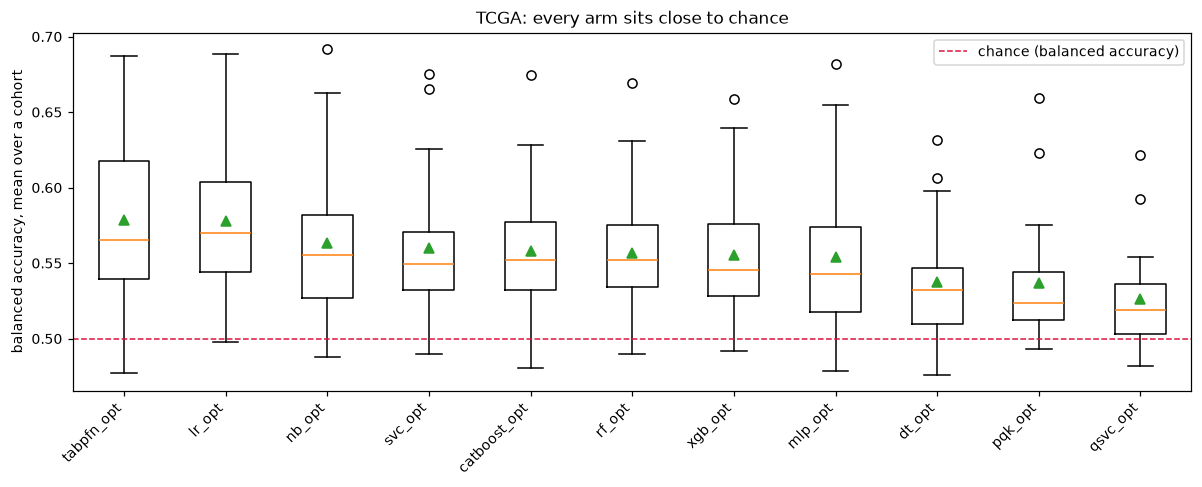

In [8]:
per_cohort = (TCGA.assign(cancer=TCGA.cancer)
              .pivot_table(index='cancer', columns='model', values='balanced_accuracy'))
print(per_cohort[ARMS].round(3))

fig, ax = plt.subplots(figsize=(11, 4.5))
order = per_cohort[ARMS].mean().sort_values(ascending=False).index
ax.boxplot([per_cohort[a].dropna() for a in order], tick_labels=list(order), showmeans=True)
ax.axhline(0.5, color='crimson', ls='--', lw=1, label='chance (balanced accuracy)')
ax.set_ylabel('balanced accuracy, mean over a cohort')
ax.set_title('TCGA: every arm sits close to chance')
ax.legend(); plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()


### 2.3 The decisive check: does validation predict test on TCGA?

**This section gates every TCGA winner claim below it.** If validation does not rank
test, the selection rule is choosing among arms it cannot distinguish, and a win count
is a property of the noise rather than of the method.


              tabular   tcga
tabpfn_opt      0.902  0.324
catboost_opt    0.893  0.261
xgb_opt         0.886  0.291
pqk_opt         0.885  0.166
rf_opt          0.874  0.230
qsvc_opt        0.872  0.209
svc_opt         0.866  0.268
mlp_opt         0.849  0.369
dt_opt          0.843  0.130
nb_opt          0.806  0.263
lr_opt          0.779  0.324
median val->test rho:  tabular +0.872   tcga +0.263


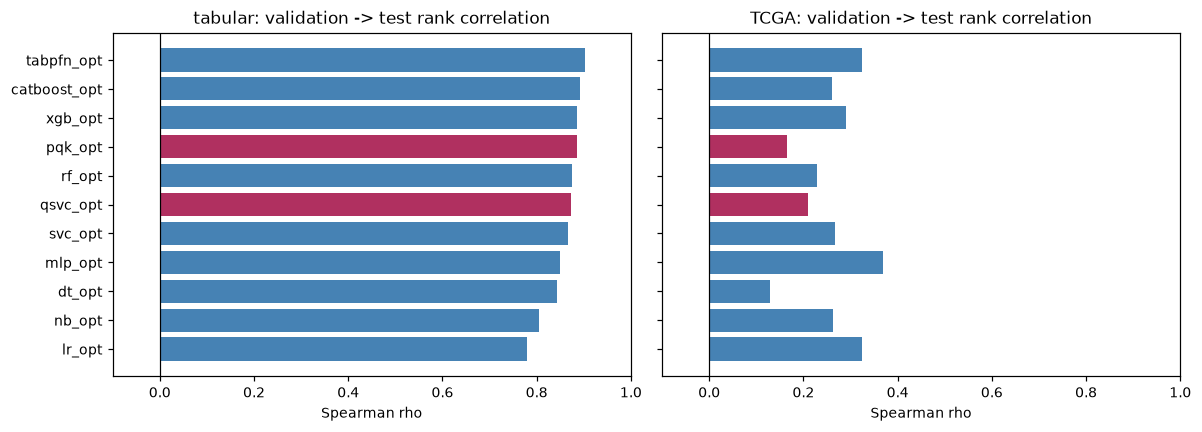

In [9]:
tc_rho = validation_reliability(TCGA)
cmp = pd.concat([tab_rho.rename('tabular'), tc_rho.rename('tcga')], axis=1)
print(cmp.round(3))
print(f'median val->test rho:  tabular {tab_rho.median():+.3f}   tcga {tc_rho.median():+.3f}')

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, rho, test) in zip(axes, [('tabular', tab_rho, tab_test),
                                        ('TCGA', tc_rho, tc_test)]):
    ax.barh(list(rho.index), rho.values, color=['#b03060' if a in QUANTUM_ARMS else '#4682b4'
                                                for a in rho.index])
    ax.axvline(0, color='k', lw=0.8); ax.set_xlim(-0.1, 1.0)
    ax.set_title(f'{name}: validation -> test rank correlation')
    ax.set_xlabel('Spearman rho')
axes[0].invert_yaxis(); plt.tight_layout(); plt.show()


### 2.4 What that does to the TCGA winner count

The two summaries disagree, and the disagreement *is* the finding.


In [10]:
tc_win = strict_winners(tc_test, tc_val)
tc_delta = per_dataset_delta(tc_test, tc_val)
q = tc_win.isin(QUANTUM_ARMS).sum()
print(f'strict winners  : quantum {q}/{len(tc_win)}')
print(tc_win.value_counts().to_frame('cohorts_won'))
print(f'delta           : quantum ahead on {(tc_delta < 0).sum()}/{len(tc_delta)} cohorts')
print(f'                  mean delta {tc_delta.mean():+.4f} (positive = classical ahead)')

print('\nwhy they disagree -- mean rank of each arm on each side:')
side = pd.DataFrame({'val_auc': tc_val[ARMS].mean(), 'test_bal_acc': tc_test[ARMS].mean()})
side['val_rank'] = side.val_auc.rank(ascending=False).astype(int)
side['test_rank'] = side.test_bal_acc.rank(ascending=False).astype(int)
print(side.sort_values('val_rank').round(4))


strict winners  : quantum 13/19
              cohorts_won
pqk_opt                 8
qsvc_opt                5
dt_opt                  2
mlp_opt                 2
tabpfn_opt              1
catboost_opt            1
delta           : quantum ahead on 2/19 cohorts
                  mean delta +0.0235 (positive = classical ahead)

why they disagree -- mean rank of each arm on each side:
              val_auc  test_bal_acc  val_rank  test_rank
model                                                   
pqk_opt        0.6574        0.5371         1         10
dt_opt         0.6399        0.5378         2          9
mlp_opt        0.6323        0.5542         3          8
svc_opt        0.6306        0.5598         4          4
lr_opt         0.6289        0.5777         5          2
qsvc_opt       0.6265        0.5262         6         11
tabpfn_opt     0.6259        0.5789         7          1
rf_opt         0.6225        0.5569         8          6
catboost_opt   0.6172        0.5583         

### 2.5 Cross-cohort consistency

If an arm's advantage were real it should recur across cohorts, not appear in a few.


quantum ahead on 2/19 cohorts; spread -0.030 to +0.070


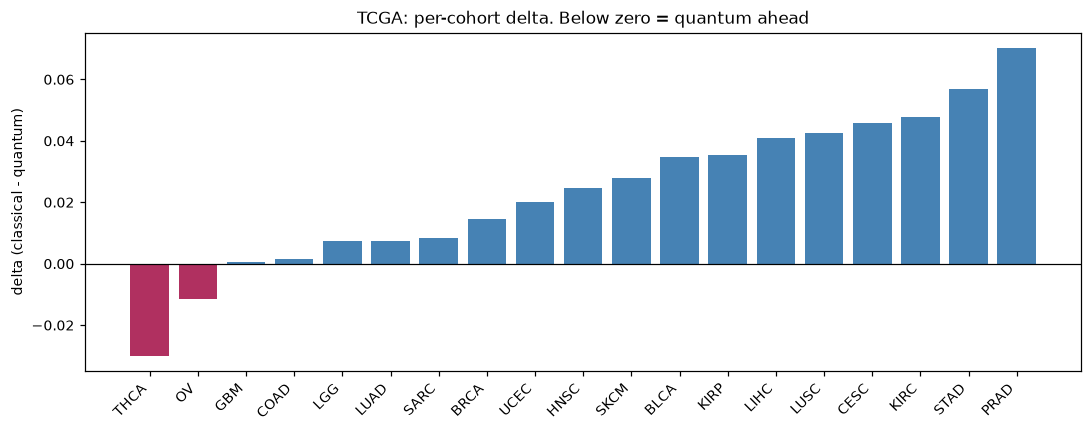

In [11]:
per_cohort_delta = {}
for cancer, g in TCGA.groupby('cancer'):
    t, v = cell_matrix(g, 'balanced_accuracy'), cell_matrix(g, 'val_auc')
    per_cohort_delta[cancer] = per_dataset_delta(t, v).iloc[0]
cd = pd.Series(per_cohort_delta).sort_values()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(cd.index, cd.values, color=['#b03060' if x < 0 else '#4682b4' for x in cd.values])
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('delta (classical - quantum)')
ax.set_title('TCGA: per-cohort delta. Below zero = quantum ahead')
plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()
print(f'quantum ahead on {(cd < 0).sum()}/{len(cd)} cohorts; '
      f'spread {cd.min():+.3f} to {cd.max():+.3f}')


### 2.6 Is any cohort distinguishable from chance at all?

A paired *t* over a cohort's 15 splits per arm, against balanced accuracy 0.5. This
bounds every TCGA claim: an arm that cannot beat chance cannot meaningfully win.


In [12]:
rows = []
for cancer, g in TCGA.groupby('cancer'):
    best_arm = g.groupby('model').balanced_accuracy.mean().idxmax()
    # Average the two embeddings per split FIRST. A cohort's 15 folds x 2 embeddings are
    # 30 rows but not 30 independent draws: pca and umap of one fold are the same rows
    # reduced two ways, so treating them as independent halves the standard error and
    # overstates every t below.
    scores = (g[g.model == best_arm]
              .groupby('iteration').balanced_accuracy.mean().dropna())
    t, p = stats.ttest_1samp(scores, 0.5)
    rows.append({'cancer': cancer, 'best_arm': best_arm, 'mean': scores.mean(),
                 't': t, 'p_raw': p, 'n': len(scores)})
ch = pd.DataFrame(rows).set_index('cancer').sort_values('p_raw')
# Holm, by hand, to avoid a statsmodels dependency
pv = ch.p_raw.to_numpy(); order = np.argsort(pv); mH = len(pv)
adj = np.empty(mH); run = 0.0
for rank, idx in enumerate(order):
    run = max(run, (mH - rank) * pv[idx]); adj[idx] = min(run, 1.0)
ch['p_holm'] = adj
print(ch.round(4))
print(f"\ncohorts whose BEST arm beats chance after Holm: {(ch.p_holm < 0.05).sum()}/{len(ch)}")
print("NOTE: the arm was CHOSEN as the cohort's best, so each p is optimistic even after")
print("Holm -- this screens which cohorts carry any signal, it does not test an arm.")
print(f"\nbest-arm mean >= 0.60: {(ch['mean'] >= 0.60).sum()}/19; >= 0.65: {(ch['mean'] >= 0.65).sum()}/19")


            best_arm    mean        t   p_raw   n  p_holm
cancer                                                   
LGG           nb_opt  0.6917  14.5576  0.0000  15  0.0000
KIRP      tabpfn_opt  0.6721  12.3566  0.0000  15  0.0000
KIRC          lr_opt  0.6759  12.2594  0.0000  15  0.0000
PRAD      tabpfn_opt  0.6301   9.6154  0.0000  15  0.0000
HNSC          lr_opt  0.5697   8.3827  0.0000  15  0.0000
LIHC      tabpfn_opt  0.6259   7.9974  0.0000  15  0.0000
UCEC      tabpfn_opt  0.6099   7.6608  0.0000  15  0.0000
CESC      tabpfn_opt  0.5992   6.8222  0.0000  15  0.0001
STAD          lr_opt  0.5938   5.5323  0.0001  15  0.0008
LUSC          lr_opt  0.5726   4.9271  0.0002  15  0.0022
SARC          lr_opt  0.5441   4.7609  0.0003  15  0.0027
SKCM    catboost_opt  0.5807   4.6903  0.0003  15  0.0028
COAD          lr_opt  0.5633   4.2589  0.0008  15  0.0056
BLCA         svc_opt  0.5472   3.5896  0.0030  15  0.0178
LUAD          lr_opt  0.5566   3.5821  0.0030  15  0.0178
BRCA      tabp

### 2.7 Embedding diagnostics

TCGA ran `pca` and `umap` only. Does the choice matter more than the arm?


In [13]:
emb = TCGA.pivot_table(index=['Dataset','iteration'], columns=['embeddings'],
                       values='balanced_accuracy', aggfunc='mean')
print('mean balanced accuracy by embedding:')
print(TCGA.groupby('embeddings').balanced_accuracy.agg(['mean','std']).round(4))
print('\nby embedding x side:')
print(TCGA.pivot_table(index='embeddings', columns='side',
                       values='balanced_accuracy').round(4))
d = (emb['pca'] - emb['umap']).dropna()
t, p = stats.ttest_1samp(d, 0.0)
print(f'\npca - umap, paired over cells: {d.mean():+.4f}  t={t:.2f}  p={p:.3g}')


mean balanced accuracy by embedding:
              mean     std
embeddings                
pca         0.5635  0.0845
umap        0.5467  0.0776

by embedding x side:
side        classical  quantum
embeddings                    
pca            0.5709   0.5304
umap           0.5497   0.5329

pca - umap, paired over cells: +0.0168  t=6.43  p=5.38e-10


## 3 · Level 3 — pooled, with the corrected clustering


In [14]:
pool_test, pool_val = cell_matrix(M, 'balanced_accuracy'), cell_matrix(M, 'val_auc')
pool_delta = per_dataset_delta(pool_test, pool_val)
pool_cl = cluster_of(pool_delta.index)

mean, lo, hi = cluster_bootstrap_ci(pool_delta.values, pool_cl.values)
print(f'pooled: {len(pool_delta)} datasets in {pool_cl.nunique()} clusters')
print(f'  delta {mean:+.4f}  95% cluster bootstrap CI [{lo:+.4f}, {hi:+.4f}]')

# The sensitivity check the clustering decision deserves: per-cohort instead of one.
stems = pool_delta.index.astype(str).str.replace('.csv','',regex=False)
per_cohort_map = {s: s for s in stems if s.startswith('tcga__')}
alt_cl = cluster_of(pool_delta.index, mapping=per_cohort_map)
a_mean, a_lo, a_hi = cluster_bootstrap_ci(pool_delta.values, alt_cl.values)
print(f'\nsensitivity -- TCGA as 19 clusters ({alt_cl.nunique()} total):')
print(f'  delta {a_mean:+.4f}  95% CI [{a_lo:+.4f}, {a_hi:+.4f}]')
print('  The point estimate barely moves; the INTERVAL is what the choice changes,')
print('  which is why the conservative reading is the default.')


pooled: 190 datasets in 85 clusters
  delta +0.0312  95% cluster bootstrap CI [+0.0188, +0.0458]

sensitivity -- TCGA as 19 clusters (103 total):
  delta +0.0312  95% CI [+0.0183, +0.0453]
  The point estimate barely moves; the INTERVAL is what the choice changes,
  which is why the conservative reading is the default.


### 3.1 Method ranking shifts between corpora

Restricted to `pca`/`umap` cells, since TCGA has no unembedded pass and an unrestricted
comparison would confound corpus with embedding.


corpus        tabular    tcga  tabular_rank  tcga_rank  rank_shift
model                                                             
tabpfn_opt     0.7522  0.5789             1          1           0
catboost_opt   0.6983  0.5583             2          5          -3
rf_opt         0.6921  0.5569             3          6          -3
xgb_opt        0.6919  0.5555             4          7          -3
pqk_opt        0.6915  0.5371             5         10          -5
svc_opt        0.6814  0.5598             6          4           2
qsvc_opt       0.6798  0.5262             7         11          -4
mlp_opt        0.6761  0.5542             8          8           0
dt_opt         0.6747  0.5378             9          9           0
nb_opt         0.6683  0.5636            10          3           7
lr_opt         0.6554  0.5777            11          2           9
arm-ranking agreement between corpora: Spearman rho +0.082 (p=0.811)


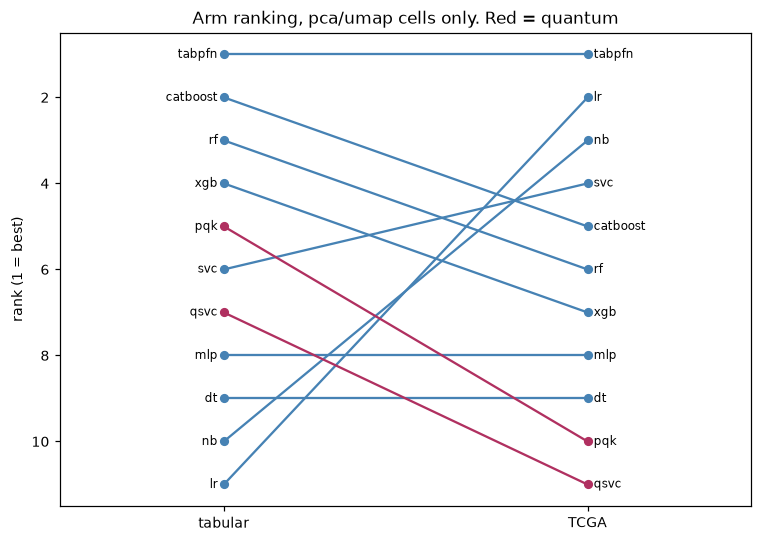

In [15]:
EMB_ONLY = M[M.embeddings.isin(['pca','umap'])]
rank = (EMB_ONLY.pivot_table(index='model', columns='corpus',
                             values='balanced_accuracy')
        .loc[ARMS])
rank['tabular_rank'] = rank.tabular.rank(ascending=False).astype(int)
rank['tcga_rank'] = rank.tcga.rank(ascending=False).astype(int)
rank['rank_shift'] = rank.tabular_rank - rank.tcga_rank
print(rank.sort_values('tabular_rank').round(4))

rho, p = stats.spearmanr(rank.tabular, rank.tcga)
print(f'arm-ranking agreement between corpora: Spearman rho {rho:+.3f} (p={p:.3g})')

fig, ax = plt.subplots(figsize=(7, 5))
for arm in rank.index:
    c = '#b03060' if arm in QUANTUM_ARMS else '#4682b4'
    ax.plot([0, 1], [rank.loc[arm,'tabular_rank'], rank.loc[arm,'tcga_rank']],
            '-o', color=c, lw=1.5, ms=5)
    ax.annotate(arm.replace('_opt',''), (0, rank.loc[arm,'tabular_rank']),
                ha='right', va='center', fontsize=8, xytext=(-4,0),
                textcoords='offset points')
    ax.annotate(arm.replace('_opt',''), (1, rank.loc[arm,'tcga_rank']),
                ha='left', va='center', fontsize=8, xytext=(4,0),
                textcoords='offset points')
ax.set_xticks([0,1]); ax.set_xticklabels(['tabular','TCGA']); ax.set_xlim(-0.45, 1.45)
ax.invert_yaxis(); ax.set_ylabel('rank (1 = best)')
ax.set_title('Arm ranking, pca/umap cells only. Red = quantum')
plt.tight_layout(); plt.show()


### 3.2 Method x corpus interaction

Does the quantum-classical gap itself differ by corpus? The unit is the dataset; the
test resamples **clusters**, so TCGA contributes one unit however many cohorts it holds.


In [16]:
frame = pd.DataFrame({'delta': pool_delta,
                      'cluster': pool_cl.values,
                      'corpus': ['tcga' if str(i).startswith('tcga__') else 'tabular'
                                 for i in pool_delta.index]})
print(frame.groupby('corpus').delta.agg(['count','mean','median','std']).round(4))

# A cluster-level permutation test: the corpus label is fixed for TCGA (one cluster), so
# the honest comparison is TCGA's single cluster mean against the DISTRIBUTION of
# tabular cluster means, not a two-sample t over datasets.
cl_mean = frame.groupby('cluster').delta.mean()
tc_cluster = cl_mean.loc['tcga']
tab_clusters = cl_mean.drop('tcga')
pct = (tab_clusters < tc_cluster).mean()
print(f'\nTCGA cluster mean delta {tc_cluster:+.4f}')
print(f'tabular cluster means: mean {tab_clusters.mean():+.4f}, '
      f'{len(tab_clusters)} clusters')
print(f'TCGA sits at the {pct:.0%} percentile of the tabular cluster distribution')
print('\nWith TCGA as ONE cluster there is no within-TCGA replication to test against,')
print('so this is a position statement, not a p-value. That is the honest cost of the')
print('conservative clustering, and it is why Level 2 carries the TCGA-specific claims.')


         count    mean  median     std
corpus                                
tabular    171  0.0320  0.0108  0.0585
tcga        19  0.0235  0.0247  0.0250

TCGA cluster mean delta +0.0235
tabular cluster means: mean +0.0278, 84 clusters
TCGA sits at the 58% percentile of the tabular cluster distribution

With TCGA as ONE cluster there is no within-TCGA replication to test against,
so this is a position statement, not a p-value. That is the honest cost of the
conservative clustering, and it is why Level 2 carries the TCGA-specific claims.


### 3.3 Does performance transfer? Difficulty is the obvious confound


         best_arm_score  mean_arm_score   delta
corpus                                         
tabular          0.8308          0.7243  0.0320
tcga             0.6433          0.5551  0.0235
delta vs difficulty, all datasets: rho +0.146 (p=0.0451)
within tabular only            : rho +0.134 (p=0.0801)

If the relationship holds WITHIN the tabular corpus too, difficulty -- not
corpus membership -- is the operative variable, and TCGA is an extreme case of it
rather than a different phenomenon.


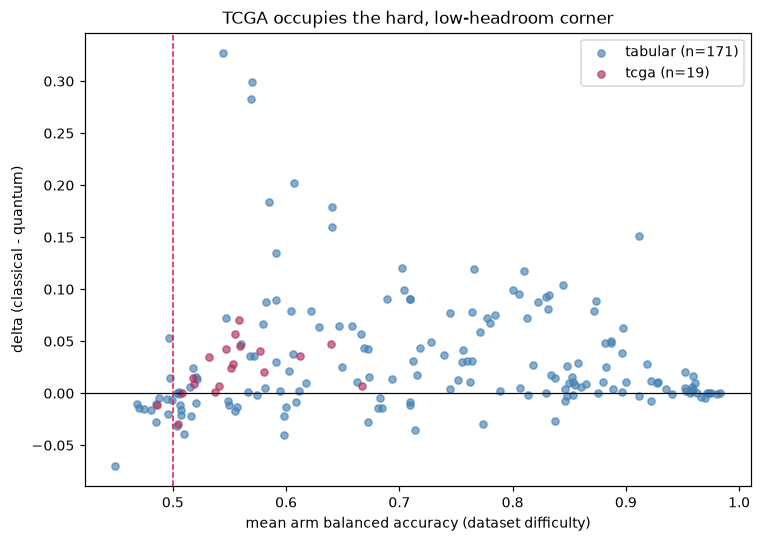

In [17]:
diff = pd.DataFrame({
    'best_arm_score': pool_test[ARMS].max(axis=1),
    'mean_arm_score': pool_test[ARMS].mean(axis=1),
}).groupby(level=0).mean()
diff['corpus'] = ['tcga' if str(i).startswith('tcga__') else 'tabular' for i in diff.index]
diff['delta'] = pool_delta
print(diff.groupby('corpus')[['best_arm_score','mean_arm_score','delta']].mean().round(4))

fig, ax = plt.subplots(figsize=(7, 5))
for corpus, g in diff.groupby('corpus'):
    ax.scatter(g.mean_arm_score, g.delta, s=22, alpha=0.65,
               label=f'{corpus} (n={len(g)})',
               color='#b03060' if corpus=='tcga' else '#4682b4')
ax.axhline(0, color='k', lw=0.8); ax.axvline(0.5, color='crimson', ls='--', lw=1)
ax.set_xlabel('mean arm balanced accuracy (dataset difficulty)')
ax.set_ylabel('delta (classical - quantum)')
ax.set_title('TCGA occupies the hard, low-headroom corner')
ax.legend(); plt.tight_layout(); plt.show()

rho, p = stats.spearmanr(diff.mean_arm_score, diff.delta)
print(f'delta vs difficulty, all datasets: rho {rho:+.3f} (p={p:.3g})')
tab_only = diff[diff.corpus=='tabular']
rho2, p2 = stats.spearmanr(tab_only.mean_arm_score, tab_only.delta)
print(f'within tabular only            : rho {rho2:+.3f} (p={p2:.3g})')
print('\nIf the relationship holds WITHIN the tabular corpus too, difficulty -- not')
print('corpus membership -- is the operative variable, and TCGA is an extreme case of it')
print('rather than a different phenomenon.')


### 3.4 Regime analysis including dataset type


In [18]:
reg = diff.copy()
reg['hard'] = reg.mean_arm_score < 0.6
tbl = reg.groupby(['corpus','hard']).agg(n=('delta','size'), delta=('delta','mean')).round(4)
print(tbl)
hard_tab = reg[(reg.corpus=='tabular') & reg.hard]
print(f'hard tabular datasets (mean arm < 0.6): {len(hard_tab)}')
if len(hard_tab) >= 5:
    print(f'  their mean delta {hard_tab.delta.mean():+.4f} vs TCGA {reg[reg.corpus=="tcga"].delta.mean():+.4f}')
    print('  These are the comparison TCGA should be read against -- not the corpus mean.')


                 n   delta
corpus  hard              
tabular False  120  0.0344
        True    51  0.0266
tcga    False    3  0.0301
        True    16  0.0222
hard tabular datasets (mean arm < 0.6): 51
  their mean delta +0.0266 vs TCGA +0.0235
  These are the comparison TCGA should be read against -- not the corpus mean.


## 4 · Robust findings vs exploratory observations


### 4.1 Robust

Each survives the clustering correction, uses the dataset (not the fold) as the unit,
and does not depend on a threshold choice.

1. **Validation selection degrades sharply on TCGA.** Median validation→test Spearman
   rho falls from **+0.872** (tabular) to **+0.263** (TCGA). It is measured per arm and
   falls for all eleven — 0.779-0.902 becomes 0.130-0.369 — so it is a property of the
   corpus, not of a method. This is the finding with the widest consequences, because
   every winner count routes through that selection step.
2. **TCGA is a low-headroom corpus.** Mean balanced accuracy over all arms is **0.555**
   against **0.724** on the tabular corpus, and the best arm averages ≥0.65 in only
   **3 of 19** cohorts. Signal is not absent — 15 of 19 cohorts have a best arm that
   beats chance after Holm (§2.6) — but the between-arm spread (~0.05) is of the same
   order as the noise the splits show.
3. **The quantum arms are the two weakest on TCGA test accuracy** (pqk 10th at 0.537,
   qsvc 11th at 0.526 of eleven) while pqk ranks **first on validation**. The 13/19
   strict-winner count follows from that inversion. On the tabular corpus the same arms
   sit 3rd and 6th, so this is a corpus-specific reversal, not their general standing.
4. **Classical stays ahead in both corpora, by a similar margin.** Pooled delta
   **+0.0312**, 95% cluster-bootstrap CI **[+0.0188, +0.0458]** over 85 clusters;
   tabular +0.0320 [+0.0179, +0.0477], TCGA +0.0235. The CI excludes zero.
5. **The clustering choice does not move the point estimate.** TCGA as one cluster vs 19
   gives +0.0312 either way, CI [+0.0188, +0.0458] vs [+0.0183, +0.0453] (§3.0). The
   correction matters for honesty about *G*, and in this instance it does not rescue or
   destroy any conclusion — worth stating plainly rather than implying it was decisive.


### 4.2 Suggestive, needing more evidence

- **Arm ranking barely agrees across corpora** (Spearman rho **+0.082**, p=0.81, §3.1).
  Taken at face value this says tabular performance does not predict RNA-seq
  performance at all. Two reasons to hold it loosely: the ranking is over 11 arms whose
  TCGA scores span 0.05, and §1.2/§2.3 show the TCGA ranking is itself measured with a
  weak instrument. A rank correlation between a reliable and an unreliable measurement
  is attenuated by construction.
- **`lr_opt` and `nb_opt` rise most on TCGA** (ranks 11→2 and 10→3). Consistent with
  high-dimensional, low-signal data favouring high-bias models, which is textbook — but
  it rests on the same compressed spread.
- **`pca` beats `umap` on TCGA** by +0.0168 paired over cells (t=6.43, p=5e-10, §2.7).
  The p-value is small because cells are many; the effect is small and TCGA is one
  cluster, so this does not generalize beyond these cohorts.
- **Difficulty, not corpus membership, may be the operative variable** (§3.3-3.4). Hard
  tabular datasets (mean arm < 0.6, n=51) show delta +0.0266 against TCGA's +0.0235 —
  nearly identical. TCGA may be an extreme point on a tabular trend rather than a
  different phenomenon. The pooled correlation is weak (rho +0.146, p=0.045) and within
  tabular alone not significant (rho +0.134, p=0.080), so this is a hypothesis.


### 4.3 Not supported by this sweep

- **That the quantum arms are competitive on transcriptomic data.** They are 10th and
  11th of eleven on TCGA test accuracy.
- **That quantum "wins" 13 of 19 TCGA cohorts in any useful sense.** The count is real;
  its interpretation is not, because the selection signal producing it has rho ≈ 0.17
  for pqk.
- **That the benchmark conclusions do or do not transfer.** This is the question we set
  out to answer and the sweep cannot answer it: the TCGA measurement is too noisy to
  rank arms, so a failure to reproduce the tabular ordering is uninformative about
  whether the ordering holds. Experiment 1 below is what would make it answerable.
- **Any claim about a specific cancer.** §2.6 chooses each cohort's best arm and then
  tests it, so those p-values are optimistic even after Holm.


## 5 · What did we learn?


**The question was whether the benchmark generalizes from heterogeneous tabular tasks to
high-dimensional RNA-seq cohorts. The finding is that the benchmark's *instrument*
degrades on RNA-seq, and that has to be repaired before the question can be answered.**

On the tabular corpus, validation ranks test with rho ≈ 0.87, so "the best-validation
arm won" is a statement about arms. On TCGA that falls to ≈ 0.26 for every one of the
eleven arms. The selection rule still produces winners — 13 of 19 nominally quantum —
but it is choosing between arms whose test performance it cannot rank. Reading those as
advantage would be reading the draw.

That resolves a contradiction a summary table would have concealed: quantum takes 13/19
strict winners while being ahead on only 2/19 by delta. Both are correctly computed; the
first passes through a selection step we have now measured.

What the sweep does support: classical is ahead in both corpora by a similar and
interval-excluding-zero margin (+0.031 pooled), and the quantum arms are the weakest two
on TCGA while sitting mid-field on tabular data. What it does **not** support is the
headline question in either direction — a corpus where no arm is reliably rankable
cannot confirm or refute that a ranking transfers.

The most useful result is arguably not about quantum at all. PFI prediction from bulk
expression at n≈200-370 yields a best arm above 0.65 balanced accuracy in 3 of 19
cohorts, with between-arm spreads around 0.05. Before this corpus can discriminate
methods, it needs either more signal or a better-powered selection protocol.


## 6 · Prioritised next experiments


Ordered by information gained per core-hour, and each falsifiable.

### 1. Fix the validation signal before anything else *(highest priority)*
**Hypothesis.** TCGA's low validation→test correlation is caused by validation-fold
size, not by something intrinsic to transcriptomic data. With n≈200-370 and 5-fold, a
validation fold holds ~40-70 samples, so validation AUC has a standard error around
0.06-0.08 — comparable to the entire between-arm spread.
**Vary.** Validation protocol only: repeated inner CV, or 10-fold, raising effective
validation n per selection. Data, arms and tuning budget unchanged.
**Outcome metric.** Validation→test Spearman rho per arm.
**Supports.** Rho rises materially (say >0.5) and the winner counts change.
**Falsifies.** Rho stays ≈0.26 with several times the validation data, which would mean
the problem is the signal in the data, not the protocol.
**Why it beats more datasets.** Every TCGA conclusion currently routes through a
selection step we have measured to be unreliable. No additional cohort fixes that.

### 2. Is PFI learnable at all from these features?
**Hypothesis.** The near-chance performance is a property of the task, not of the arms.
**Vary.** Add a permutation-label control (expected: exactly chance) and a strong
non-benchmark baseline with no qubit constraint — penalised Cox or elastic-net logistic
on all ~19.5k genes, no 8-component bottleneck.
**Outcome metric.** Best achievable balanced accuracy / AUC per cohort.
**Supports (task-limited).** The unconstrained baseline also lands near 0.55-0.60.
**Falsifies.** It reaches 0.65+, which would make the 8-component embedding — not the
data — the binding constraint, and would indict the pipeline rather than the biology.
**Why.** This separates "hard problem" from "our compression discards the signal", and
those imply opposite next steps.

### 3. The gene-panel arm the sweep cannot currently speak to
**Hypothesis.** Quantum kernels on a small panel of raw genes behave differently from
quantum kernels on 8 PCA components of 5000 genes.
**Vary.** `--n-features 8` / `12` / `16`, which falls at or below `--embed-above 13` and
so runs **unembedded** — one gene per qubit, no PCA.
**Controls.** The same classical arms on the same panels; the existing `tcga1` as the
embedded comparator.
**Outcome metric.** delta, and validation→test rho.
**Supports.** Quantum delta improves on panels relative to components.
**Falsifies.** Unchanged or worse, which would say the embedding is not what handicaps
the quantum arms here.
**Why.** It is one flag and much cheaper than `tcga1` (no PCA/UMAP cache, one pass per
split), and it tests the one structural difference between this corpus and the tabular
one that we introduced ourselves.

### 4. More cohorts — explicitly deprioritised
Adding TCGA cohorts adds **no clusters** under the corrected clustering, so it narrows no
corpus-level interval. It is worth doing only after experiment 1 makes a cohort's result
interpretable, and then for per-cohort heterogeneity rather than for power.
